# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import os
import matplotlib.ticker as mtick
import warnings
warnings.filterwarnings("ignore")

#### Chart Presets 
Creating chart presets that will eb inherited by the entire charts in this notebook.

In [2]:
PRESETS = {
    "colors": {
        "primary":    "#2A6F97",   # default bars / points
        "highlight":  "#E07A1F",   # callouts and the Large-aircraft colour
        "reference":  "#D1495B",   # mean / benchmark lines
        "text":       "#1F2933",   # titles and labels
        "muted":      "#6B7785",   # subtitles, ticks, annotations
        "grid":       "#E4E7EB",   # gridlines
        "background": "#FFFFFF",   # figure and axes background
    },
    "size_colors": {"Small": "#2A6F97", "Large": "#E07A1F"},
    "categorical": ["#2A6F97", "#E07A1F", "#3A9D8F", "#8E6BBF",
                    "#D1495B", "#C9A227", "#4F6D7A", "#7BA05B"],
    "fonts": {
        "family": "DejaVu Sans",
        "title": 14, "subtitle": 10.5, "label": 11, "tick": 9.5, "annotation": 8.5,
    },
    "sizes": {
        "wide": (17, 4.6),         # three-panel overview row
        "pair": (15, 6.5),         # two-panel comparison row
        "single": (12, 5.5),       # one wide chart
        "bar_width": 0.72,
        "point": 5,
    },
    "percent_axes": True,
    "save_charts": False,
    "output_dir": "charts",
}

# number formatters
def thousands(v, pos=None):
    return f"{v:,.0f}"

def rate_fmt():
    """Axis formatter for rates stored as fractions (0-1)."""
    return mtick.PercentFormatter(1.0, decimals=0) if PRESETS["percent_axes"] else mtick.FormatStrFormatter("%.2f")

# global theme
def apply_theme():
    """Apply the PRESETS look globally through matplotlib (plt) settings."""
    c, f = PRESETS["colors"], PRESETS["fonts"]
    plt.style.use("default")
    plt.rcParams.update({
        "font.family": f["family"],
        "axes.prop_cycle": plt.cycler(color=PRESETS["categorical"]),
        "figure.facecolor": c["background"], "axes.facecolor": c["background"],
        "axes.edgecolor": c["grid"], "axes.labelcolor": c["text"],
        "axes.labelsize": f["label"], "axes.titlesize": f["title"],
        "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
        "xtick.color": c["muted"], "ytick.color": c["muted"],
        "xtick.labelsize": f["tick"], "ytick.labelsize": f["tick"],
        "grid.color": c["grid"], "grid.linewidth": 0.9,
        "text.color": c["text"], "legend.frameon": False,
        "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    })

# shared presets
def style_ax(ax, title=None, xlabel=None, ylabel=None, subtitle=None,
             x_fmt=None, y_fmt=None, grid_axis="y"):
    """Title, labels, clean spines, formatters and gridlines for ONE axes."""
    c, f = PRESETS["colors"], PRESETS["fonts"]
    if title:
        ax.set_title(title, loc="left", fontsize=f["title"], fontweight="bold",
                     color=c["text"], pad=26 if subtitle else 12)
    if subtitle:
        ax.text(0, 1.015, subtitle, transform=ax.transAxes, fontsize=f["subtitle"],
                color=c["muted"], va="bottom", ha="left")
    if xlabel is not None: ax.set_xlabel(xlabel, labelpad=8)
    if ylabel is not None: ax.set_ylabel(ylabel, labelpad=8)
    if x_fmt is not None: ax.xaxis.set_major_formatter(x_fmt)
    if y_fmt is not None: ax.yaxis.set_major_formatter(y_fmt)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.grid(False)
    if grid_axis in ("x", "y", "both"):
        ax.grid(axis=grid_axis, color=c["grid"])
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    return ax

def save_chart(fig, name):
    if PRESETS["save_charts"]:
        os.makedirs(PRESETS["output_dir"], exist_ok=True)
        fig.savefig(os.path.join(PRESETS["output_dir"], f"{name}.png"))

def show_chart(fig, name="chart"):
    """Tidy the layout, optionally save, then display."""
    fig.tight_layout()
    save_chart(fig, name)
    plt.show()

def barh_ci(ax, tbl, value, lo, hi, title, color, xlabel=None):
    """Horizontal bar chart with 95% CI whiskers and sample-size labels; lowest value at the top."""
    c, f = PRESETS["colors"], PRESETS["fonts"]
    if tbl.empty:
        ax.text(0.5, 0.5, "No groups meet the minimum sample size", ha="center", va="center")
        ax.set_title(title); ax.axis("off")
        return
    tbl = tbl.sort_values(value, ascending=False)
    xerr = np.vstack([tbl[value] - tbl[lo], tbl[hi] - tbl[value]])
    ax.barh(tbl.index.astype(str), tbl[value], xerr=xerr, color=color, alpha=0.9,
            height=PRESETS["sizes"]["bar_width"], capsize=3,
            error_kw=dict(ecolor=c["muted"], elinewidth=1.1))
    for y, (_, row) in enumerate(tbl.iterrows()):
        ax.text(row[hi] + 0.012, y, f"n={int(row['n'])}", va="center",
                fontsize=f["annotation"], color=c["muted"])
    ax.set_xlim(0, min(1.15, tbl[hi].max() + 0.15))
    style_ax(ax, title, xlabel, "", x_fmt=rate_fmt(), grid_axis="x")

apply_theme()
# print("Chart presets loaded.")

## Exploratory Data Analysis  
- Load in the cleaned data

In [3]:
# laod dataset 
clean_df = pd.read_csv("./data/AviationData_cleaned.csv", parse_dates=["Event.Date"], low_memory=False)

In [4]:
# preview the dataset
clean_df.head()

,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Airport.Code,Airport.Name,Injury.Severity,Aircraft.Damage,...,Report.Status,Publication.Date,Event.Year,Total.Passengers,Total.Fatal.Serious,Fatal.Serious.Rate,Fatal.Rate,Destroyed,Model.Family,Aircraft.Type
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,ONP,NEWPORT MUNICIPAL,Non-Fatal,Substantial,...,Probable Cause,NaN,1983,4.0,0.0,0.0,0.0,0,182,CESSNA 182
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,3YR,MUNICIPAL,Non-Fatal,Substantial,...,Probable Cause,NaN,1983,2.0,0.0,0.0,0.0,0,182,CESSNA 182
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,78Y,RANKIN,Non-Fatal,Substantial,...,Probable Cause,NaN,1983,1.0,0.0,0.0,0.0,0,182,CESSNA 182
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,CCB,CABLE,Non-Fatal,Substantial,...,Probable Cause,NaN,1983,2.0,0.0,0.0,0.0,0,PA28,PIPER PA28
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,NaN,SPRINGBROOK,Non-Fatal,Substantial,...,Probable Cause,NaN,1983,2.0,0.0,0.0,0.0,0,140,CESSNA 140


In [5]:
# preview the tail 
clean_df.tail()

,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Airport.Code,Airport.Name,Injury.Severity,Aircraft.Damage,...,Report.Status,Publication.Date,Event.Year,Total.Passengers,Total.Fatal.Serious,Fatal.Serious.Rate,Fatal.Rate,Destroyed,Model.Family,Aircraft.Type
54158,20221213106455,Accident,WPR23LA065,2022-12-13,"Lewistown, MT",United States,KLWT,Lewiston Municipal Airport,Non-Fatal,Substantial,...,NaN,14-12-2022,2022,1.0,0.0,0.0,0.0,0,PA42,PIPER PA42
54159,20221215106463,Accident,ERA23LA090,2022-12-14,"San Juan, PR",United States,SIG,FERNANDO LUIS RIBAS DOMINICCI,Non-Fatal,Substantial,...,NaN,27-12-2022,2022,1.0,0.0,0.0,0.0,0,SR22,CIRRUS SR22
54160,20221219106475,Accident,WPR23LA069,2022-12-15,"Wichita, KS",United States,ICT,WICHITA DWIGHT D EISENHOWER NT,Non-Fatal,Substantial,...,NaN,19-12-2022,2022,1.0,0.0,0.0,0.0,0,SA226,SWEARINGEN SA226
54161,20221219106470,Accident,ERA23LA091,2022-12-16,"Brooksville, FL",United States,BKV,BROOKSVILLE-TAMPA BAY RGNL,Minor,Substantial,...,NaN,23-12-2022,2022,1.0,1.0,1.0,0.0,0,R172,CESSNA R172
54162,20221227106497,Accident,WPR23LA075,2022-12-26,"Payson, AZ",United States,PAN,PAYSON,Non-Fatal,Substantial,...,NaN,27-12-2022,2022,1.0,0.0,0.0,0.0,0,8,AMERICAN CHAMPION AIRCRAFT 8


In [6]:
# show all columns 
clean_df.columns

Index(['Event.Id', 'Investigation.Type', 'Accident.Number', 'Event.Date',
       'Location', 'Country', 'Airport.Code', 'Airport.Name',
       'Injury.Severity', 'Aircraft.Damage', 'Aircraft.Category',
       'Registration.Number', 'Make', 'Model', 'Amateur.Built',
       'Number.of.Engines', 'Engine.Type', 'Purpose.of.flight',
       'Total.Fatal.Injuries', 'Total.Serious.Injuries',
       'Total.Minor.Injuries', 'Total.Uninjured', 'Weather.Condition',
       'Broad.phase.of.flight', 'Report.Status', 'Publication.Date',
       'Event.Year', 'Total.Passengers', 'Total.Fatal.Serious',
       'Fatal.Serious.Rate', 'Fatal.Rate', 'Destroyed', 'Model.Family',
       'Aircraft.Type'],
      dtype='object')

In [7]:
# shape and other dataset details 
print("Shape:", clean_df.shape)
clean_df.info()
clean_df[["Total.Passengers", "Fatal.Serious.Rate", "Fatal.Rate", "Destroyed"]].describe()

Shape: (54163, 34)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54163 entries, 0 to 54162
Data columns (total 34 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Event.Id                54163 non-null  object        
 1   Investigation.Type      54163 non-null  object        
 2   Accident.Number         54163 non-null  object        
 3   Event.Date              54163 non-null  datetime64[ns]
 4   Location                54144 non-null  object        
 5   Country                 54090 non-null  object        
 6   Airport.Code            33060 non-null  object        
 7   Airport.Name            34570 non-null  object        
 8   Injury.Severity         54163 non-null  object        
 9   Aircraft.Damage         54163 non-null  object        
 10  Aircraft.Category       54163 non-null  object        
 11  Registration.Number     53686 non-null  object        
 12  Make                    541

,Total.Passengers,Fatal.Serious.Rate,Fatal.Rate,Destroyed
count,54163.000000,54163.000000,54163.000000,54163.000000
mean,3.273175,0.275236,0.178386,0.207743
std,15.578350,0.431593,0.372823,0.405696
min,1.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000,0.000000
50%,2.000000,0.000000,0.000000,0.000000
75%,2.000000,0.750000,0.000000,0.000000
max,576.000000,1.000000,1.000000,1.000000


In [8]:
# helper functions and global variables

PASSENGER_THRESHOLD = 20   # plane types with more than this many people aboard in an accident are "Large"
MIN_SAMPLE = 10            # minimum accidents per group before we report or compare it

def wilson_ci(successes, n, z=1.96):
    """95% Wilson confidence interval for a proportion (works well for small samples)."""
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

def summarize(data, by, min_n=MIN_SAMPLE):
    """Per-group sample size, mean fatal/serious fraction (+95% CI) and destroyed rate (+95% CI).
    Groups with fewer than min_n accidents are dropped so we never compare tiny samples."""
    out = data.groupby(by).agg(
        n=("Event.Id", "size"),
        mean_fsr=("Fatal.Serious.Rate", "mean"),
        sd_fsr=("Fatal.Serious.Rate", "std"),
        destroyed=("Destroyed", "sum"),
    )
    out["destroyed_rate"] = out["destroyed"] / out["n"]
    half = 1.96 * out["sd_fsr"] / np.sqrt(out["n"])
    out["fsr_lo"] = (out["mean_fsr"] - half).clip(lower=0)
    out["fsr_hi"] = (out["mean_fsr"] + half).clip(upper=1)
    out["destroyed_lo"], out["destroyed_hi"] = wilson_ci(out["destroyed"], out["n"])
    return out[out["n"] >= min_n]

def shortlist(stats, k=5):
    """Rank groups on BOTH metrics (fatal/serious fraction and destroyed rate); lowest average rank is best."""
    t = stats.copy()
    t["avg_rank"] = (t["mean_fsr"].rank() + t["destroyed_rate"].rank()) / 2
    cols = ["n", "mean_fsr", "destroyed_rate", "avg_rank"]
    return t.sort_values(["avg_rank", "n"], ascending=[True, False]).head(k)[cols]

def print_shortlists(stats_by_size, label):
    for size in ["Small", "Large"]:
        base = clean_df[clean_df["Aircraft.Size"] == size]
        print(f"=== {size.upper()} AIRCRAFT ({label}) ===")
        print(f"All {size.lower()} aircraft: {len(base)} accidents | fatal/serious fraction {base['Fatal.Serious.Rate'].mean():.1%} "
              f"| destroyed {base['Destroyed'].mean():.1%}  <- benchmark")
        t = stats_by_size[size]
        if t.empty:
            print(f"No {label.lower()} has at least {MIN_SAMPLE} accidents.\n")
            continue
        sl = shortlist(t)
        display(sl.round(3))
        best = sl.index[0]
        r = sl.iloc[0]
        print(f"Best combined rank: {best} (n={int(r['n'])}, fatal/serious {r['mean_fsr']:.1%}, destroyed {r['destroyed_rate']:.1%})\n")

**Overall structure of the data**
- Accidents per year, and the distribution of the two outcome measures: the fraction of occupants fatally/seriously injured and whether the aircraft was destroyed.

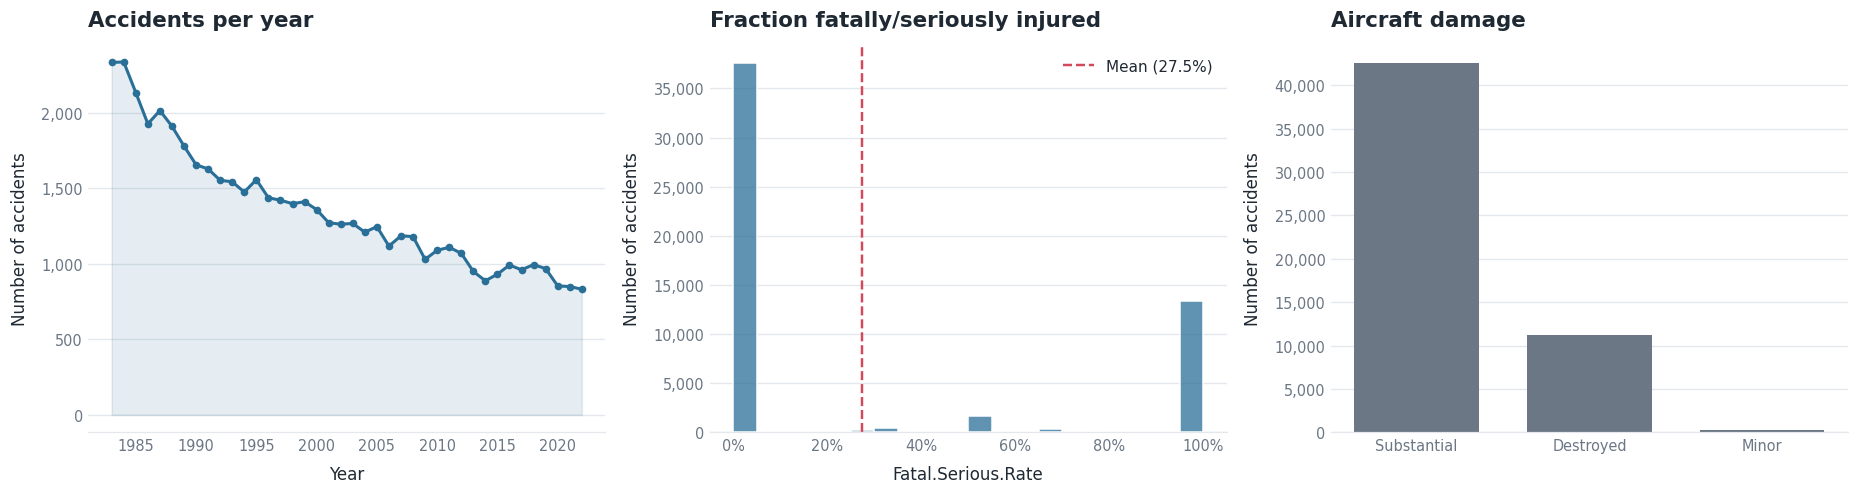

Overall destroyed rate: 20.8%
Overall mean fatal/serious fraction: 27.5%
Share of accidents with a rate of exactly 0 or 1: 94.0%


In [9]:
fig, axes = plt.subplots(1, 3, figsize=PRESETS["sizes"]["wide"])
col = PRESETS["colors"]

per_year = clean_df["Event.Year"].value_counts().sort_index()
axes[0].plot(per_year.index, per_year.values, color=col["primary"], marker="o", markersize=4, linewidth=2)
axes[0].fill_between(per_year.index, per_year.values, color=col["primary"], alpha=0.12)
style_ax(axes[0], "Accidents per year", "Year", "Number of accidents", y_fmt=mtick.FuncFormatter(thousands))

sns.histplot(clean_df["Fatal.Serious.Rate"], bins=20, color=col["primary"], edgecolor="white", ax=axes[1])
axes[1].axvline(clean_df["Fatal.Serious.Rate"].mean(), color=col["reference"], linestyle="--", linewidth=1.6,
                label=f"Mean ({clean_df['Fatal.Serious.Rate'].mean():.1%})")
axes[1].legend()
style_ax(axes[1], "Fraction fatally/seriously injured", "Fatal.Serious.Rate", "Number of accidents",
         x_fmt=rate_fmt(), y_fmt=mtick.FuncFormatter(thousands))

dmg = clean_df["Aircraft.Damage"].value_counts()
axes[2].bar(dmg.index, dmg.values, color=col["muted"], width=PRESETS["sizes"]["bar_width"])
style_ax(axes[2], "Aircraft damage", "", "Number of accidents", y_fmt=mtick.FuncFormatter(thousands))

show_chart(fig, "eda_overview")

print(f"Overall destroyed rate: {clean_df['Destroyed'].mean():.1%}")
print(f"Overall mean fatal/serious fraction: {clean_df['Fatal.Serious.Rate'].mean():.1%}")
print(f"Share of accidents with a rate of exactly 0 or 1: {clean_df['Fatal.Serious.Rate'].isin([0, 1]).mean():.1%}")

Most accidents are either "nobody badly hurt" (rate 0) or "everyone badly hurt" (rate 1), and many involve only one or two people aboard, so rates for individual accidents are coarse. This is why every comparison below reports a sample size and a 95% confidence interval, and why groups with fewer than 10 accidents are excluded.

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [10]:
# Classify each plane TYPE (Make + Model family) by the largest number of people recorded aboard
# in any of its accidents. Classifying by type (not by accident) keeps e.g. a 737 "Large" even when
# one particular accident only had a few people on board.
max_aboard = clean_df.groupby("Aircraft.Type")["Total.Passengers"].max()
large_types = max_aboard[max_aboard > PASSENGER_THRESHOLD].index
clean_df["Aircraft.Size"] = np.where(clean_df["Aircraft.Type"].isin(large_types), "Large", "Small")

size_summary = clean_df.groupby("Aircraft.Size").agg(
    accidents=("Event.Id", "size"),
    plane_types=("Aircraft.Type", "nunique"),
    makes=("Make", "nunique"),
    mean_aboard=("Total.Passengers", "mean"),
)
display(size_summary.round(2))

# Sanity check: which types were classified as Large?
print("Large plane types and their accident counts:")
print(clean_df[clean_df["Aircraft.Size"] == "Large"]["Aircraft.Type"].value_counts().head(20))

,accidents,plane_types,makes,mean_aboard
Aircraft.Size,,,,
Large,6299,61,15,13.36
Small,47864,710,63,1.95


Large plane types and their accident counts:
Aircraft.Type
PIPER PA28                4410
PIPER PA23                 472
BEECH 95                   262
BOEING 737                 165
BEECH 1900                  65
BEECH S35                   64
DE HAVILLAND DHC6           62
LEARJET 35                  62
BOMBARDIER CL600            61
DOUGLAS DC3                 58
BOEING 747                  45
DE HAVILLAND DHC3           44
CESSNA 441                  40
SWEARINGEN SA226            40
BOEING 757                  35
BOEING 767                  30
BOEING 727                  28
MCDONNELL DOUGLAS MD11      28
MCDONNELL DOUGLAS DC9       26
FAIRCHILD SA227             26
Name: count, dtype: int64


Classification rule: a plane type (Make + Model family) is **Large** if any recorded accident of that type had more than 20 people aboard (`Total.Passengers` > 20), otherwise **Small**. A make can therefore appear in both groups. Check the list of Large types above; if a clearly small plane appears there (a data-entry error), raise the rule to require several such accidents.

#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

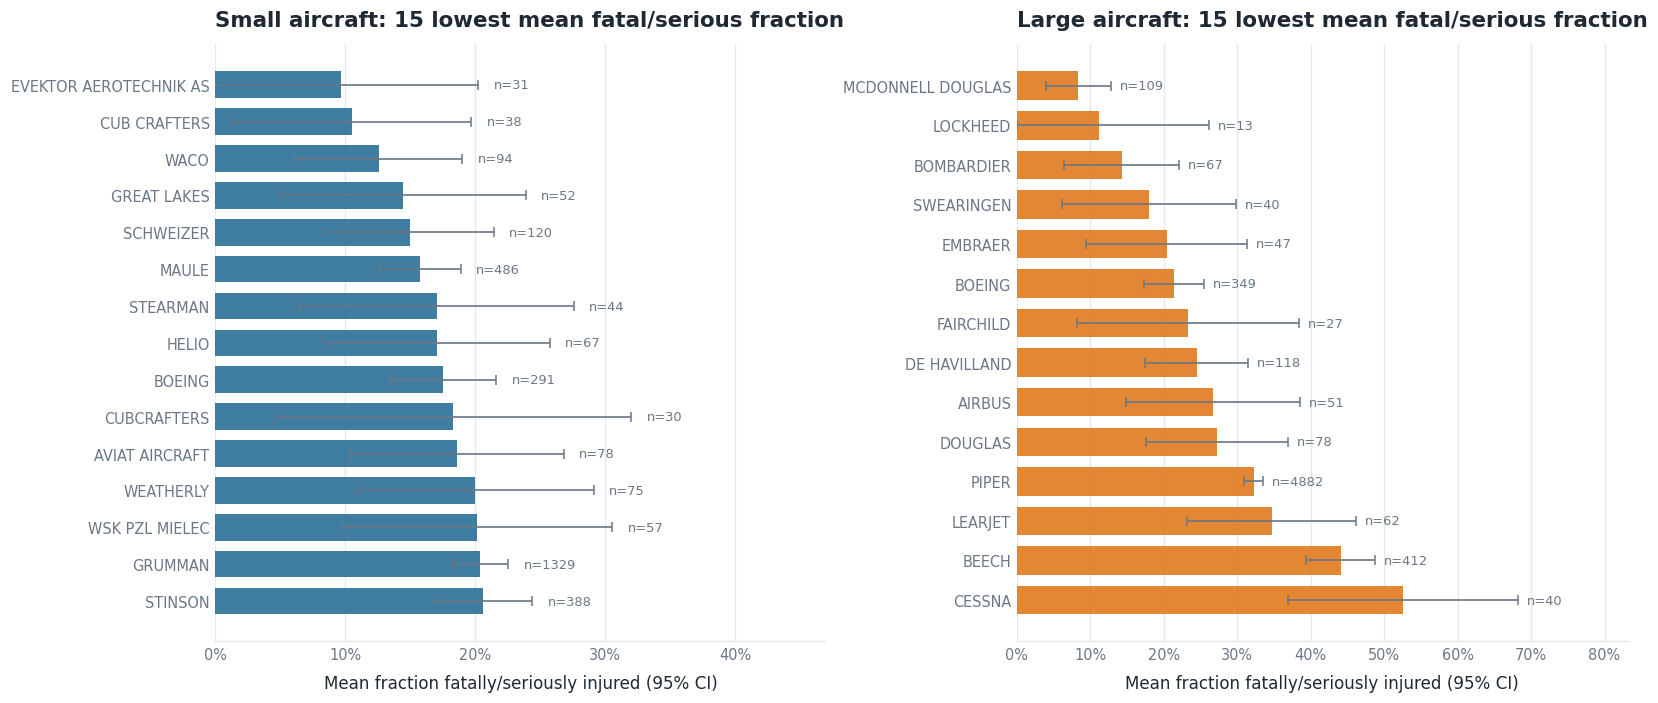

Small aircraft: 60 makes have >= 10 accidents


,n,mean_fsr,fsr_lo,fsr_hi
Make,,,,
EVEKTOR AEROTECHNIK AS,31,0.097,0.000,0.203
CUB CRAFTERS,38,0.105,0.014,0.197
WACO,94,0.126,0.062,0.190
GREAT LAKES,52,0.144,0.050,0.239
SCHWEIZER,120,0.150,0.086,0.214
MAULE,486,0.158,0.127,0.189
STEARMAN,44,0.170,0.065,0.276
HELIO,67,0.171,0.084,0.257
BOEING,291,0.175,0.134,0.216


Large aircraft: 14 makes have >= 10 accidents


,n,mean_fsr,fsr_lo,fsr_hi
Make,,,,
MCDONNELL DOUGLAS,109,0.084,0.040,0.128
LOCKHEED,13,0.112,0.000,0.262
BOMBARDIER,67,0.143,0.065,0.221
SWEARINGEN,40,0.180,0.061,0.299
EMBRAER,47,0.204,0.094,0.314
BOEING,349,0.215,0.174,0.255
FAIRCHILD,27,0.233,0.083,0.384
DE HAVILLAND,118,0.245,0.174,0.315
AIRBUS,51,0.268,0.149,0.386


In [11]:
# Mean fatal/serious fraction per make, within each size group (makes need >= MIN_SAMPLE accidents)
make_stats = {size: summarize(clean_df[clean_df["Aircraft.Size"] == size], "Make")
              for size in ["Small", "Large"]}
top_makes = {size: t.nsmallest(15, "mean_fsr") for size, t in make_stats.items()}

fig, axes = plt.subplots(1, 2, figsize=PRESETS["sizes"]["pair"])
for ax, size in zip(axes, ["Small", "Large"]):
    barh_ci(ax, top_makes[size], "mean_fsr", "fsr_lo", "fsr_hi",
            f"{size} aircraft: 15 lowest mean fatal/serious fraction", PRESETS["size_colors"][size],
            xlabel="Mean fraction fatally/seriously injured (95% CI)")
show_chart(fig, "makes_fatal_serious")

for size in ["Small", "Large"]:
    print(f"{size} aircraft: {len(make_stats[size])} makes have >= {MIN_SAMPLE} accidents")
    display(top_makes[size][["n", "mean_fsr", "fsr_lo", "fsr_hi"]].round(3))

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

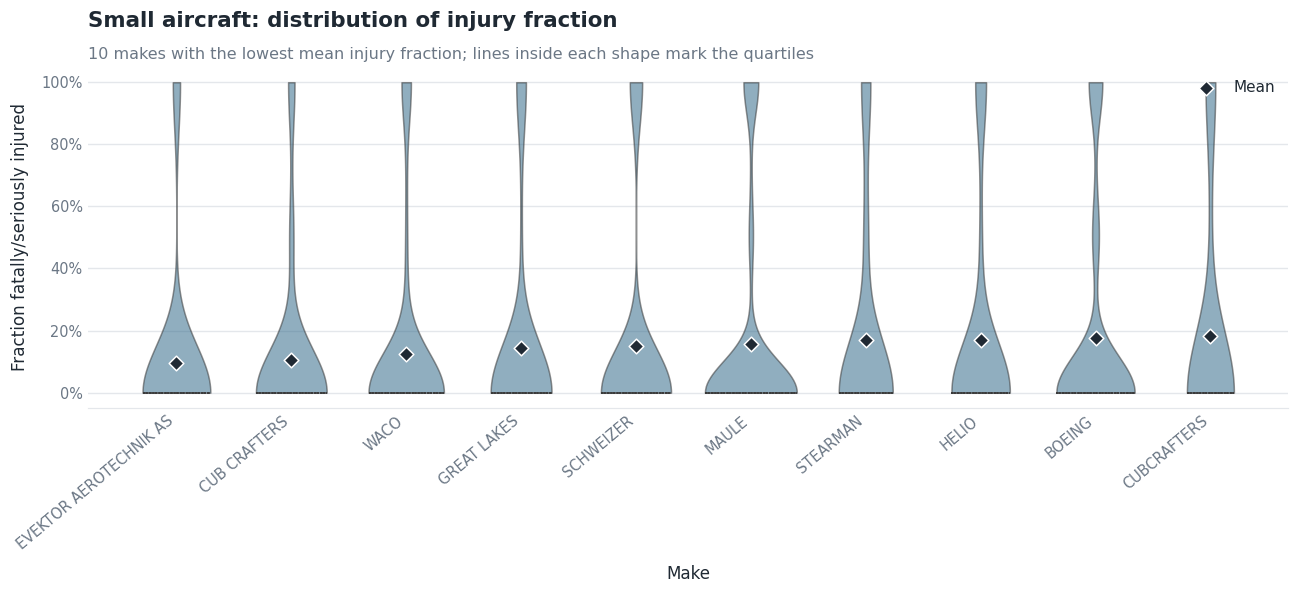

In [12]:
top10_small = make_stats["Small"].nsmallest(10, "mean_fsr").index.tolist()
sub = clean_df[(clean_df["Aircraft.Size"] == "Small") & clean_df["Make"].isin(top10_small)]
col = PRESETS["colors"]

fig, ax = plt.subplots(figsize=PRESETS["sizes"]["single"])
sns.violinplot(data=sub, x="Make", y="Fatal.Serious.Rate", order=top10_small, cut=0,
               color=PRESETS["size_colors"]["Small"], saturation=0.8, inner="quartile",
               linewidth=1, ax=ax)
for patch in ax.collections:
    patch.set_alpha(0.55)
means = [sub.loc[sub["Make"] == m, "Fatal.Serious.Rate"].mean() for m in top10_small]
ax.scatter(range(len(top10_small)), means, marker="D", s=46, color=col["text"], zorder=5,
           edgecolor="white", label="Mean")
ax.legend(loc="upper right")
ax.tick_params(axis="x", rotation=40)
for lbl in ax.get_xticklabels():
    lbl.set_ha("right")
style_ax(ax, "Small aircraft: distribution of injury fraction",
         "Make", "Fraction fatally/seriously injured",
         subtitle="10 makes with the lowest mean injury fraction; lines inside each shape mark the quartiles",
         y_fmt=rate_fmt(), grid_axis="y")
show_chart(fig, "small_makes_violin")

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

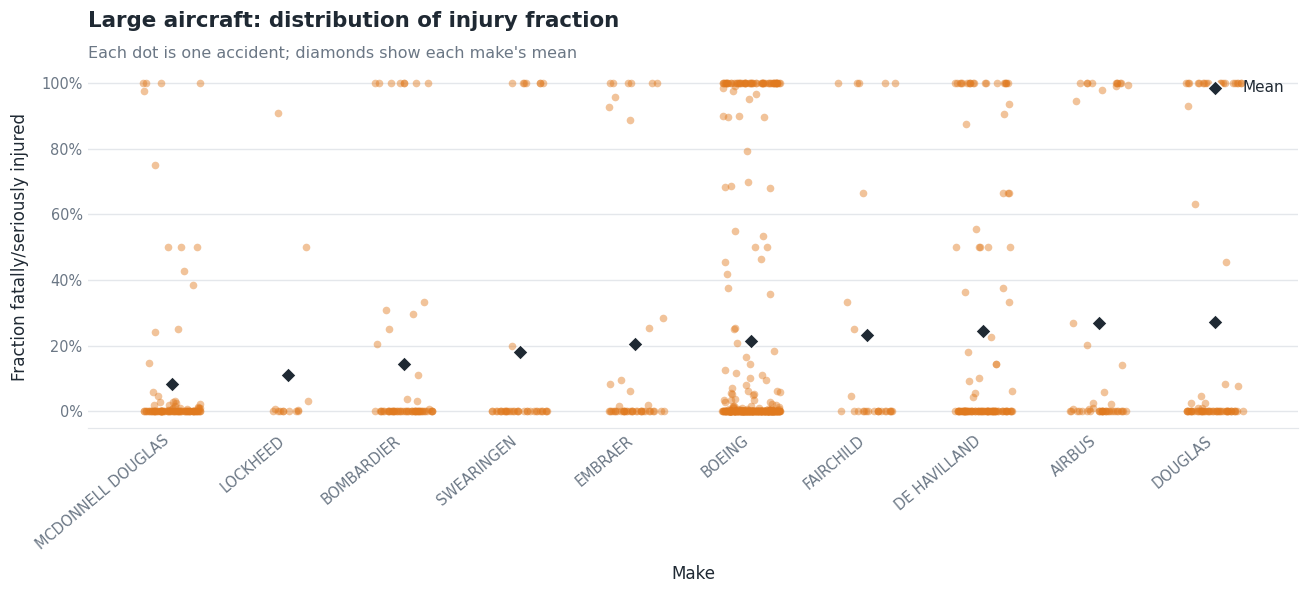

In [13]:
top10_large = make_stats["Large"].nsmallest(10, "mean_fsr").index.tolist()
sub = clean_df[(clean_df["Aircraft.Size"] == "Large") & clean_df["Make"].isin(top10_large)]
col = PRESETS["colors"]

if sub.empty:
    print("No large makes meet the minimum sample size.")
else:
    fig, ax = plt.subplots(figsize=PRESETS["sizes"]["single"])
    sns.stripplot(data=sub, x="Make", y="Fatal.Serious.Rate", order=top10_large, jitter=0.25,
                  alpha=0.45, size=PRESETS["sizes"]["point"], color=PRESETS["size_colors"]["Large"], ax=ax)
    means = [sub.loc[sub["Make"] == m, "Fatal.Serious.Rate"].mean() for m in top10_large]
    ax.scatter(range(len(top10_large)), means, marker="D", s=52, color=col["text"], zorder=5,
               edgecolor="white", label="Mean")
    ax.legend(loc="upper right")
    ax.tick_params(axis="x", rotation=40)
    for lbl in ax.get_xticklabels():
        lbl.set_ha("right")
    style_ax(ax, "Large aircraft: distribution of injury fraction",
             "Make", "Fraction fatally/seriously injured",
             subtitle="Each dot is one accident; diamonds show each make's mean",
             y_fmt=rate_fmt(), grid_axis="y")
    show_chart(fig, "large_makes_strip")

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

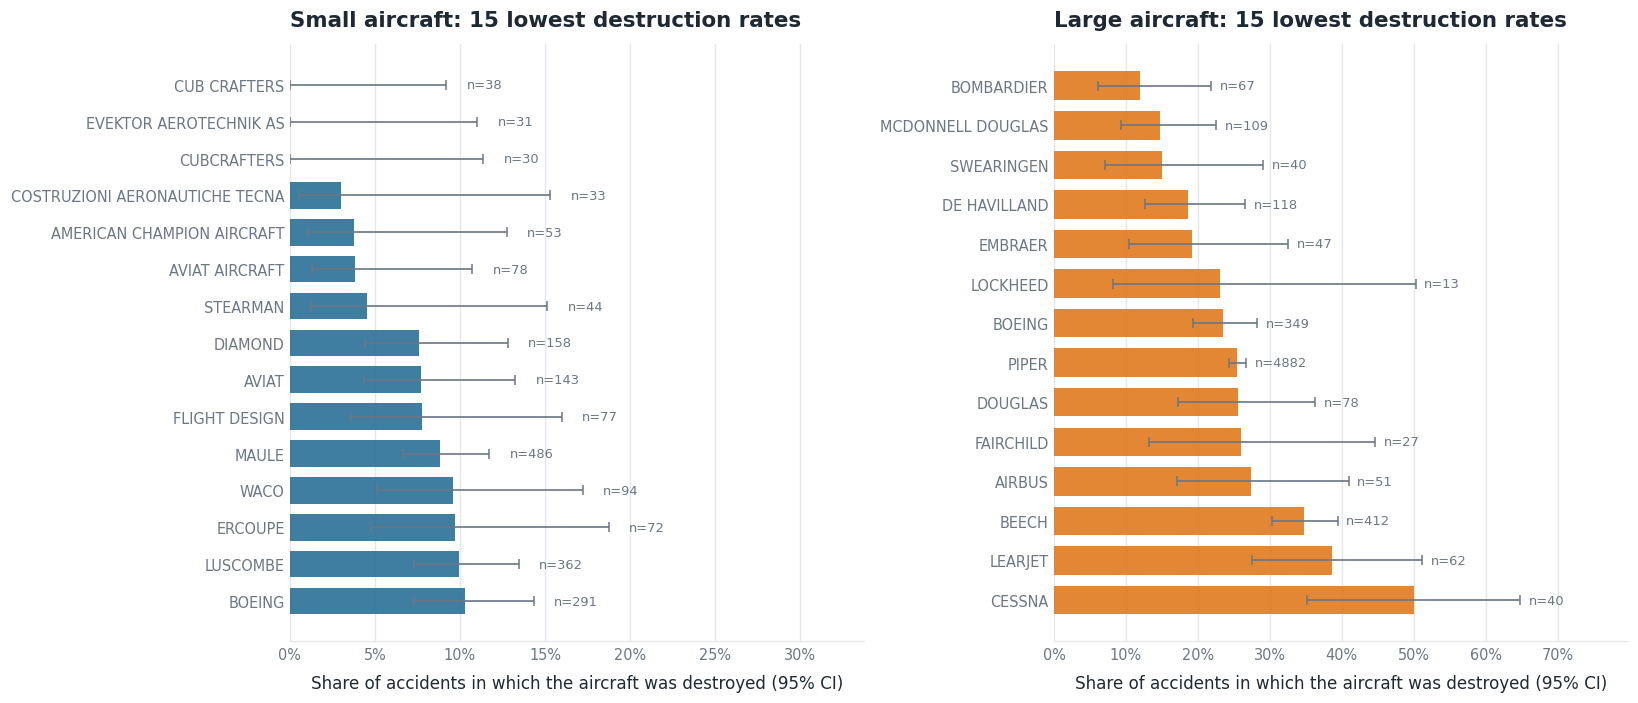

Small aircraft


,n,destroyed_rate,destroyed_lo,destroyed_hi
Make,,,,
CUB CRAFTERS,38,0.000,0.000,0.092
CUBCRAFTERS,30,0.000,-0.000,0.114
EVEKTOR AEROTECHNIK AS,31,0.000,-0.000,0.110
COSTRUZIONI AERONAUTICHE TECNA,33,0.030,0.005,0.153
AMERICAN CHAMPION AIRCRAFT,53,0.038,0.010,0.128
AVIAT AIRCRAFT,78,0.038,0.013,0.107
STEARMAN,44,0.045,0.013,0.151
DIAMOND,158,0.076,0.044,0.128
AVIAT,143,0.077,0.043,0.132


Large aircraft


,n,destroyed_rate,destroyed_lo,destroyed_hi
Make,,,,
BOMBARDIER,67,0.119,0.062,0.218
MCDONNELL DOUGLAS,109,0.147,0.092,0.225
SWEARINGEN,40,0.150,0.071,0.291
DE HAVILLAND,118,0.186,0.126,0.266
EMBRAER,47,0.191,0.104,0.325
LOCKHEED,13,0.231,0.082,0.503
BOEING,349,0.235,0.194,0.282
PIPER,4882,0.255,0.243,0.267
DOUGLAS,78,0.256,0.173,0.363


In [14]:
# Destruction rate by make (95% Wilson confidence interval), lowest 15 per size group
top_destroyed = {size: t.nsmallest(15, "destroyed_rate") for size, t in make_stats.items()}

fig, axes = plt.subplots(1, 2, figsize=PRESETS["sizes"]["pair"])
for ax, size in zip(axes, ["Small", "Large"]):
    barh_ci(ax, top_destroyed[size], "destroyed_rate", "destroyed_lo", "destroyed_hi",
            f"{size} aircraft: 15 lowest destruction rates", PRESETS["size_colors"][size],
            xlabel="Share of accidents in which the aircraft was destroyed (95% CI)")
show_chart(fig, "makes_destroyed")

for size in ["Small", "Large"]:
    print(f"{size} aircraft")
    display(top_destroyed[size][["n", "destroyed_rate", "destroyed_lo", "destroyed_hi"]].round(3))

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

In [15]:
# Data-driven summary: rank each make on BOTH metrics (injury fraction and destruction rate)
print_shortlists(make_stats, "Makes")

=== SMALL AIRCRAFT (Makes) ===
All small aircraft: 47864 accidents | fatal/serious fraction 27.0% | destroyed 20.1%  <- benchmark


,n,mean_fsr,destroyed_rate,avg_rank
Make,,,,
EVEKTOR AEROTECHNIK AS,31,0.097,0.000,1.5
CUB CRAFTERS,38,0.105,0.000,2.0
CUBCRAFTERS,30,0.183,0.000,6.0
STEARMAN,44,0.170,0.045,7.0
WACO,94,0.126,0.096,7.5


Best combined rank: EVEKTOR AEROTECHNIK AS (n=31, fatal/serious 9.7%, destroyed 0.0%)

=== LARGE AIRCRAFT (Makes) ===
All large aircraft: 6299 accidents | fatal/serious fraction 31.5% | destroyed 25.7%  <- benchmark


,n,mean_fsr,destroyed_rate,avg_rank
Make,,,,
MCDONNELL DOUGLAS,109,0.084,0.147,1.5
BOMBARDIER,67,0.143,0.119,2.0
SWEARINGEN,40,0.180,0.150,3.5
LOCKHEED,13,0.112,0.231,4.0
EMBRAER,47,0.204,0.191,5.0


Best combined rank: MCDONNELL DOUGLAS (n=109, fatal/serious 8.4%, destroyed 14.7%)



**Discussion: makes**

*Write your interpretation here after running the cells above (the numbers change with your data). Suggested points:*
- Which small and large makes combine a low fatal/serious fraction with a low destruction rate (see the shortlist tables)? Name them and quote the rates and sample sizes.
- How do these rates compare with the benchmark for all small / all large aircraft?
- Do the confidence-interval whiskers of the best makes overlap with the next ones down? If so, say the ranking is not statistically clear-cut.
- What do the violin and strip plots show: are results driven by many mild accidents, or by a few extreme ones? Note that rates are 0 or 1 in many accidents.
- Caveat: accident data has no denominator of flights flown, so these are rates *given an accident*, not overall crash risk. Popular makes with many accidents are not necessarily less safe.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

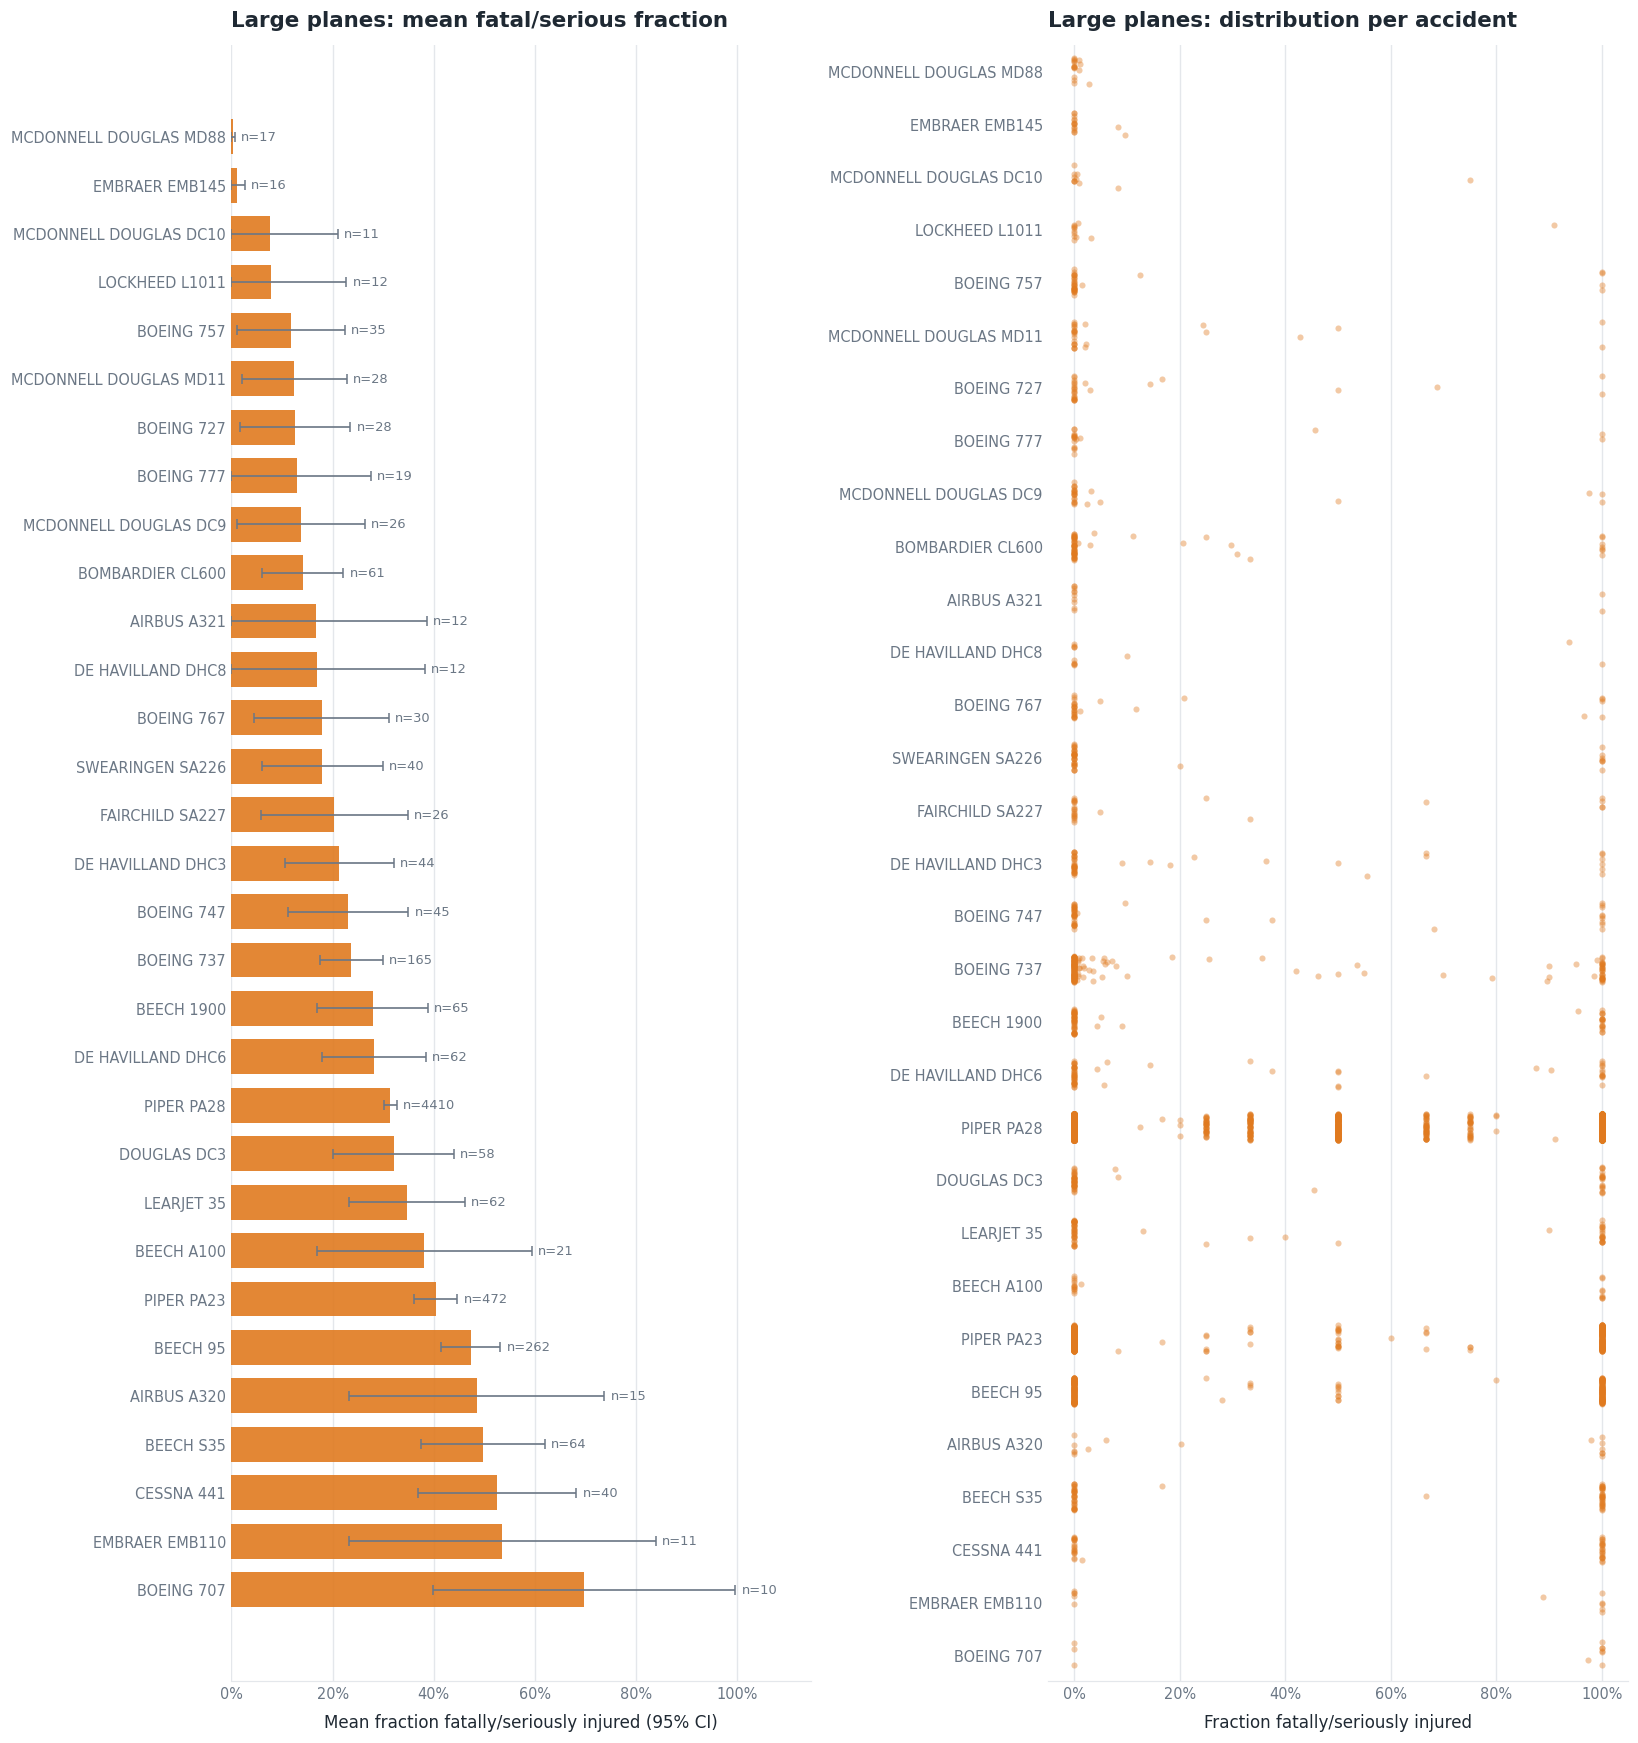

,n,mean_fsr,fsr_lo,fsr_hi,destroyed_rate
Aircraft.Type,,,,,
MCDONNELL DOUGLAS MD88,17,0.003,0.000,0.007,0.000
EMBRAER EMB145,16,0.011,0.000,0.026,0.000
MCDONNELL DOUGLAS DC10,11,0.077,0.000,0.210,0.091
LOCKHEED L1011,12,0.079,0.000,0.227,0.167
BOEING 757,35,0.118,0.012,0.225,0.114
MCDONNELL DOUGLAS MD11,28,0.124,0.021,0.228,0.214
BOEING 727,28,0.127,0.018,0.235,0.143
BOEING 777,19,0.130,0.000,0.276,0.211
MCDONNELL DOUGLAS DC9,26,0.138,0.011,0.264,0.231


In [16]:
type_stats = {size: summarize(clean_df[clean_df["Aircraft.Size"] == size], "Aircraft.Type")
              for size in ["Small", "Large"]}

def type_panel(size, top_n=None):
    color = PRESETS["size_colors"][size]
    tbl = type_stats[size]
    if top_n:
        tbl = tbl.nsmallest(top_n, "mean_fsr")
    if tbl.empty:
        print(f"No {size.lower()} plane types have >= {MIN_SAMPLE} accidents.")
        return
    order = tbl.sort_values("mean_fsr").index.tolist()
    sub = clean_df[(clean_df["Aircraft.Size"] == size) & clean_df["Aircraft.Type"].isin(order)]

    fig, axes = plt.subplots(1, 2, figsize=(PRESETS["sizes"]["pair"][0], max(4, 0.45 * len(order) + 2)))
    barh_ci(axes[0], tbl, "mean_fsr", "fsr_lo", "fsr_hi", f"{size} planes: mean fatal/serious fraction",
            color, xlabel="Mean fraction fatally/seriously injured (95% CI)")
    sns.stripplot(data=sub, y="Aircraft.Type", x="Fatal.Serious.Rate", order=order,
                  jitter=0.25, alpha=0.4, size=PRESETS["sizes"]["point"] - 1, ax=axes[1], color=color)
    style_ax(axes[1], f"{size} planes: distribution per accident", "Fraction fatally/seriously injured", "",
             x_fmt=rate_fmt(), grid_axis="x")
    show_chart(fig, f"types_{size.lower()}")
    display(tbl.sort_values("mean_fsr")[["n", "mean_fsr", "fsr_lo", "fsr_hi", "destroyed_rate"]].round(3))

type_panel("Large")

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

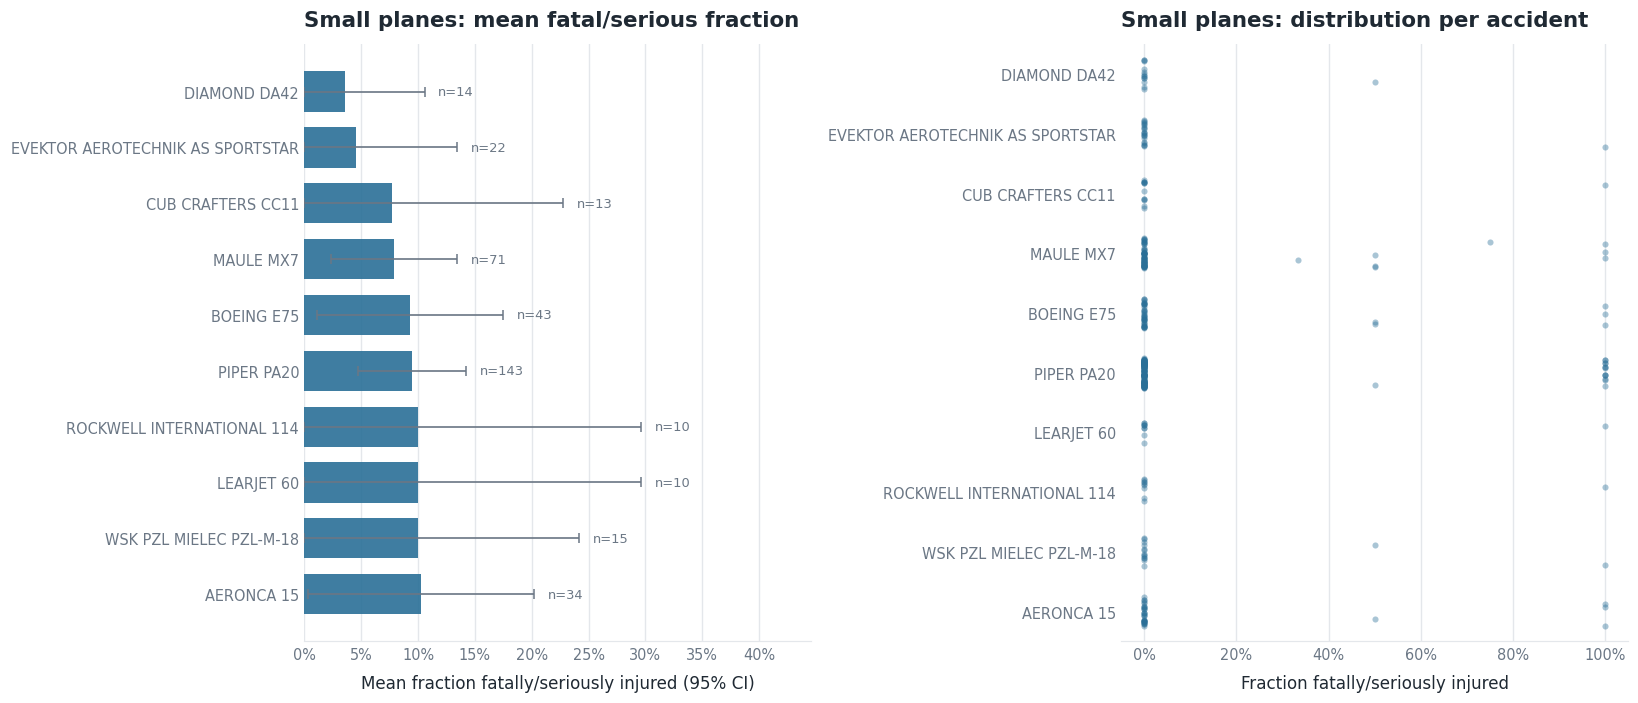

,n,mean_fsr,fsr_lo,fsr_hi,destroyed_rate
Aircraft.Type,,,,,
DIAMOND DA42,14,0.036,0.000,0.106,0.000
EVEKTOR AEROTECHNIK AS SPORTSTAR,22,0.045,0.000,0.135,0.000
CUB CRAFTERS CC11,13,0.077,0.000,0.228,0.000
MAULE MX7,71,0.079,0.023,0.134,0.014
BOEING E75,43,0.093,0.011,0.175,0.116
PIPER PA20,143,0.094,0.047,0.142,0.063
LEARJET 60,10,0.100,0.000,0.296,0.100
ROCKWELL INTERNATIONAL 114,10,0.100,0.000,0.296,0.000
WSK PZL MIELEC PZL-M-18,15,0.100,0.000,0.242,0.200


In [17]:
# Small planes: only the 10 types with the lowest mean fatal/serious fraction (each with >= MIN_SAMPLE accidents)
type_panel("Small", top_n=10)

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

In [18]:
# Data-driven summary: rank each plane type on BOTH metrics (injury fraction and destruction rate)
print_shortlists(type_stats, "Plane types")

=== SMALL AIRCRAFT (Plane types) ===
All small aircraft: 47864 accidents | fatal/serious fraction 27.0% | destroyed 20.1%  <- benchmark


,n,mean_fsr,destroyed_rate,avg_rank
Aircraft.Type,,,,
DIAMOND DA42,14,0.036,0.000,3.25
EVEKTOR AEROTECHNIK AS SPORTSTAR,22,0.045,0.000,3.75
CUB CRAFTERS CC11,13,0.077,0.000,4.25
ROCKWELL INTERNATIONAL 114,10,0.100,0.000,6.75
MAULE MX7,71,0.079,0.014,7.50


Best combined rank: DIAMOND DA42 (n=14, fatal/serious 3.6%, destroyed 0.0%)

=== LARGE AIRCRAFT (Plane types) ===
All large aircraft: 6299 accidents | fatal/serious fraction 31.5% | destroyed 25.7%  <- benchmark


,n,mean_fsr,destroyed_rate,avg_rank
Aircraft.Type,,,,
MCDONNELL DOUGLAS MD88,17,0.003,0.000,1.25
EMBRAER EMB145,16,0.011,0.000,1.75
MCDONNELL DOUGLAS DC10,11,0.077,0.091,3.00
BOEING 757,35,0.118,0.114,5.00
LOCKHEED L1011,12,0.079,0.167,6.75


Best combined rank: MCDONNELL DOUGLAS MD88 (n=17, fatal/serious 0.3%, destroyed 0.0%)



**Discussion: specific airplane types**

*Write your interpretation here after running the cells above (the numbers change with your data). Suggested points:*
- Name the recommended small and large plane types (Make + Model family) and quote their fatal/serious fraction, destruction rate and sample size.
- Are the differences between the best types larger than their confidence intervals? State how confident you are.
- Do any types look good on one metric but poor on the other (for example survivable injuries but frequent destruction)?
- Mention the sample-size filter (at least 10 accidents per type) and why types below it are not recommended either way.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

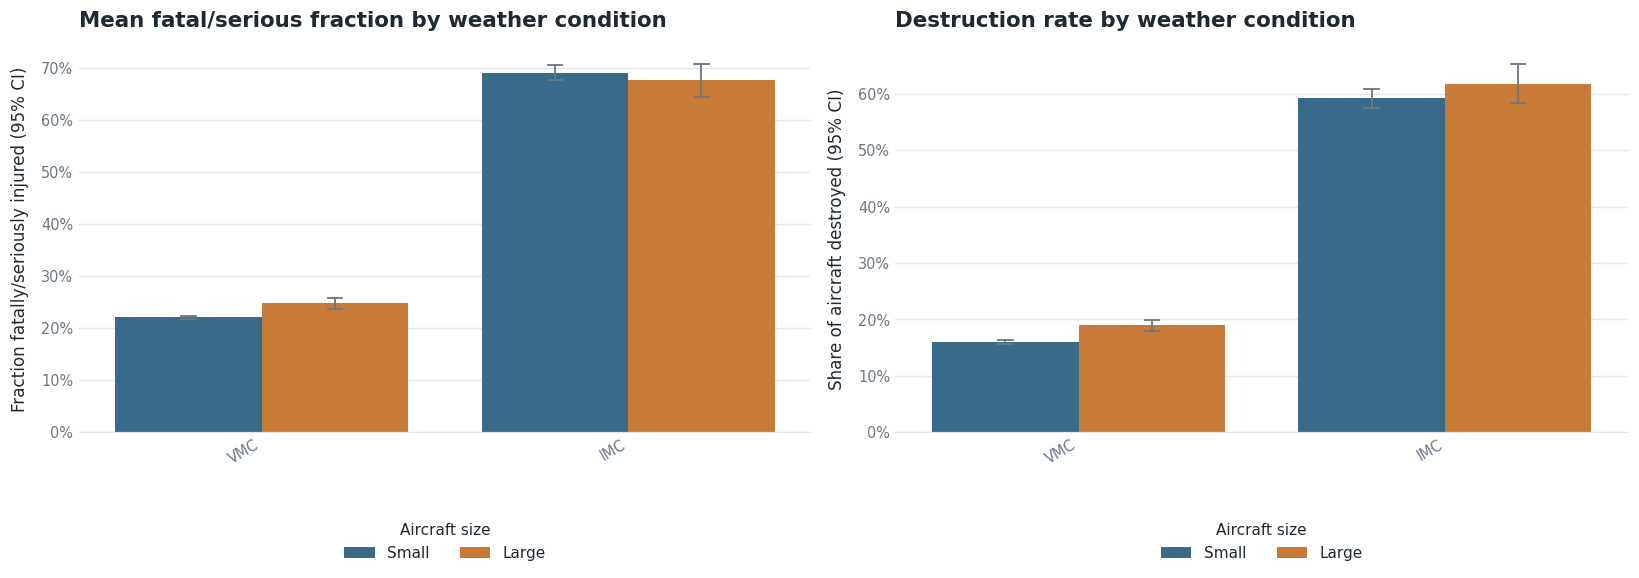

n  mean_fsr  fsr_lo  fsr_hi  \
Weather.Condition Aircraft.Size                                    
IMC               Large            751     0.676   0.644   0.708   
                  Small           3496     0.691   0.676   0.706   
VMC               Large           5105     0.248   0.237   0.259   
                  Small          42697     0.220   0.217   0.224   

                                 destroyed_rate  destroyed_lo  destroyed_hi  
Weather.Condition Aircraft.Size                                              
IMC               Large                   0.618         0.583         0.652  
                  Small                   0.592         0.575         0.608  
VMC               Large                   0.190         0.179         0.201  
                  Small                   0.160         0.156         0.163

Large aircraft - weather condition: destroyed vs category chi-square p = 0.0000; fatal/serious fraction Kruskal-Wallis p = 0.0000
Small aircraft - weather condition: destroyed vs category chi-square p = 0.0000; fatal/serious fraction Kruskal-Wallis p = 0.0000
(p < 0.05 suggests the category matters; association is not proof of cause.)


In [19]:
FACTOR_MIN_N = 30   # minimum accidents per (category, size group) cell for factor comparisons

def factor_analysis(factor, label=None, min_n=FACTOR_MIN_N):
    label = label or factor
    sub = clean_df.dropna(subset=[factor]).copy()
    sub[factor] = sub[factor].astype(str)

    # keep only (category, size) cells with enough accidents
    counts = sub.groupby([factor, "Aircraft.Size"]).size()
    keep = counts[counts >= min_n].index
    sub = sub[sub.set_index([factor, "Aircraft.Size"]).index.isin(keep)]
    if sub.empty:
        print(f"No {label} categories have >= {min_n} accidents in a size group.")
        return

    order = sub.groupby(factor)["Fatal.Serious.Rate"].mean().sort_values().index.tolist()
    pal = PRESETS["size_colors"]
    fig, axes = plt.subplots(1, 2, figsize=(PRESETS["sizes"]["pair"][0], 5.5))
    sns.barplot(data=sub, x=factor, y="Fatal.Serious.Rate", hue="Aircraft.Size", order=order,
                hue_order=["Small", "Large"], palette=pal, errorbar=("ci", 95), capsize=0.08,
                err_kws={"linewidth": 1.2, "color": PRESETS["colors"]["muted"]}, ax=axes[0])
    style_ax(axes[0], f"Mean fatal/serious fraction by {label}", "", "Fraction fatally/seriously injured (95% CI)",
             y_fmt=rate_fmt(), grid_axis="y")
    sns.barplot(data=sub, x=factor, y="Destroyed", hue="Aircraft.Size", order=order,
                hue_order=["Small", "Large"], palette=pal, errorbar=("ci", 95), capsize=0.08,
                err_kws={"linewidth": 1.2, "color": PRESETS["colors"]["muted"]}, ax=axes[1])
    style_ax(axes[1], f"Destruction rate by {label}", "", "Share of aircraft destroyed (95% CI)",
             y_fmt=rate_fmt(), grid_axis="y")
    for ax in axes:
        ax.tick_params(axis="x", rotation=30)
        for lbl in ax.get_xticklabels():
            lbl.set_ha("right")
        ax.legend(title="Aircraft size", loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
    show_chart(fig, f"factor_{factor.replace('.', '_').lower()}")

    tbl = summarize(sub, [factor, "Aircraft.Size"], min_n=min_n)
    display(tbl[["n", "mean_fsr", "fsr_lo", "fsr_hi", "destroyed_rate", "destroyed_lo", "destroyed_hi"]].round(3))

    # Significance tests within each size group (skipped if scipy is not installed)
    try:
        from scipy import stats
    except ImportError:
        print("scipy not installed: skipping significance tests.")
        return
    for size, g in sub.groupby("Aircraft.Size"):
        if g[factor].nunique() < 2:
            continue
        try:
            ct = pd.crosstab(g[factor], g["Destroyed"])
            p_chi = stats.chi2_contingency(ct)[1] if ct.shape[1] == 2 else float("nan")
            p_kw = stats.kruskal(*[x["Fatal.Serious.Rate"].values for _, x in g.groupby(factor)])[1]
            print(f"{size} aircraft - {label}: destroyed vs category chi-square p = {p_chi:.4f}; "
                  f"fatal/serious fraction Kruskal-Wallis p = {p_kw:.4f}")
        except ValueError as e:
            print(f"{size} aircraft - test not possible: {e}")
    print("(p < 0.05 suggests the category matters; association is not proof of cause.)")

# ---- Factor 1: Weather condition (VMC = visual, IMC = instrument conditions) ----
factor_analysis("Weather.Condition", "weather condition")

**Factor 1: Weather condition**

*Write your interpretation here after running the cells above (the numbers change with your data). Suggested points:*
- Do accidents in IMC (poor visibility) have a higher fatal/serious fraction and destruction rate than in VMC? Quote the values and sample sizes.
- Does the pattern hold for both small and large aircraft? Is the difference larger than the confidence intervals, and what do the p-values say?
- Caveat: weather is missing for a large share of accidents, and IMC flying is more common in some kinds of flights, so this is an association only.

---
**Factor 2: Phase of flight**

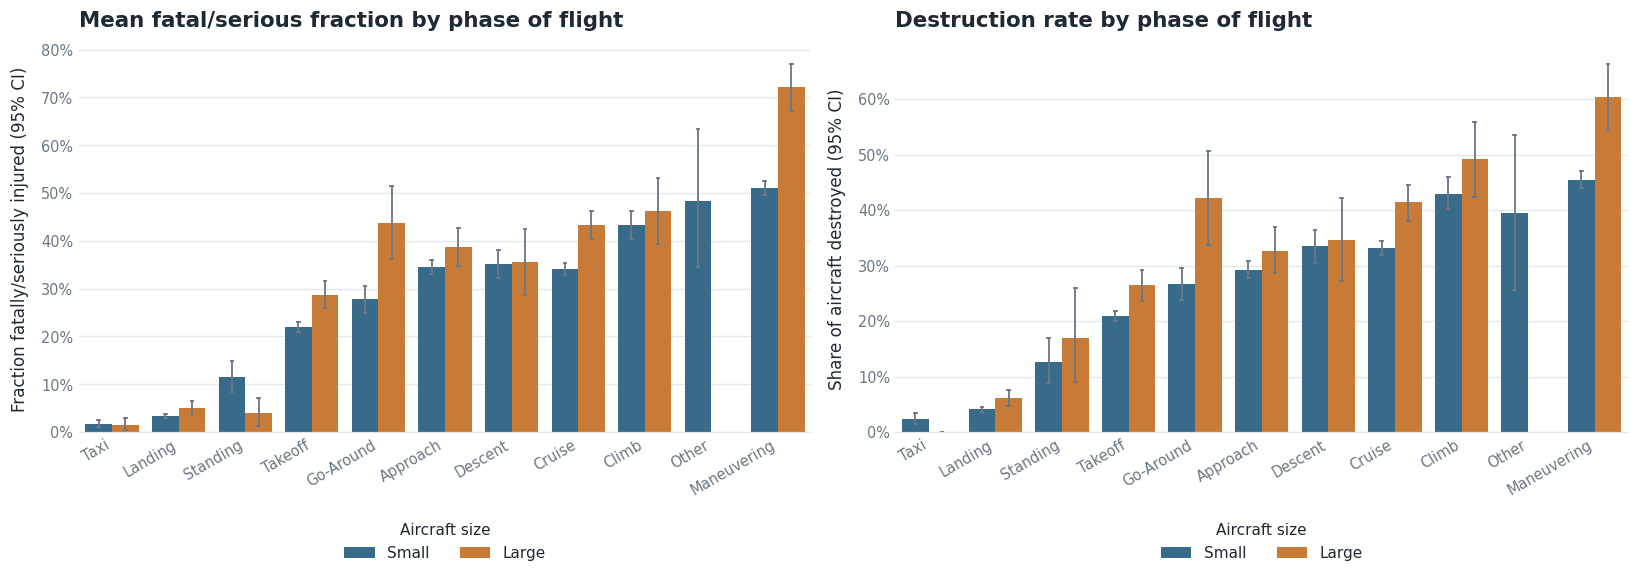

n  mean_fsr  fsr_lo  fsr_hi  \
Broad.phase.of.flight Aircraft.Size                                   
Approach              Large           537     0.388   0.348   0.428   
                      Small          3442     0.345   0.330   0.361   
Climb                 Large           177     0.462   0.393   0.532   
                      Small          1013     0.434   0.404   0.463   
Cruise                Large           906     0.433   0.402   0.464   
                      Small          5460     0.340   0.328   0.353   
Descent               Large           147     0.355   0.280   0.430   
                      Small           968     0.351   0.322   0.381   
Go-Around             Large           142     0.438   0.360   0.515   
                      Small           940     0.279   0.251   0.306   
Landing               Large           986     0.050   0.037   0.063   
                      Small          9787     0.034   0.030   0.037   
Maneuvering           Large           268     0.722   0.670   0.773   
                      Small          3904     0.511   0.496   0.526   
Other                 Small            43     0.483   0.336   0.630   
Standing              Large            77     0.039   0.007   0.071   
                      Small           284     0.115   0.083   0.147   
Takeoff               Large           924     0.286   0.258   0.314   
                      Small          7021     0.220   0.210   0.229   
Taxi                  Large           169     0.015   0.001   0.029   
                      Small           964     0.017   0.010   0.025   

                                     destroyed_rate  destroyed_lo  \
Broad.phase.of.flight Aircraft.Size                                 
Approach              Large                   0.326         0.288   
                      Small                   0.292         0.277   
Climb                 Large                   0.492         0.419   
                      Small                   0.429         0.399   
Cruise                Large                   0.414         0.382   
                      Small                   0.333         0.320   
Descent               Large                   0.347         0.275   
                      Small                   0.335         0.306   
Go-Around             Large                   0.423         0.344   
                      Small                   0.267         0.240   
Landing               Large                   0.062         0.048   
                      Small                   0.041         0.037   
Maneuvering           Large                   0.604         0.545   
                      Small                   0.455         0.439   
Other                 Small                   0.395         0.264   
Standing              Large                   0.169         0.101   
                      Small                   0.127         0.093   
Takeoff               Large                   0.265         0.238   
                      Small                   0.209         0.200   
Taxi                  Large                   0.000         0.000   
                      Small                   0.024         0.016   

                                     destroyed_hi  
Broad.phase.of.flight Aircraft.Size                
Approach              Large                 0.367  
                      Small                 0.307  
Climb                 Large                 0.565  
                      Small                 0.460  
Cruise                Large                 0.446  
                      Small                 0.345  
Descent               Large                 0.427  
                      Small                 0.365  
Go-Around             Large                 0.505  
                      Small                 0.296  
Landing               Large                 0.079  
                      Small                 0.045  
Maneuvering           Large                 0.661  
                      Small           

Large aircraft - phase of flight: destroyed vs category chi-square p = 0.0000; fatal/serious fraction Kruskal-Wallis p = 0.0000
Small aircraft - phase of flight: destroyed vs category chi-square p = 0.0000; fatal/serious fraction Kruskal-Wallis p = 0.0000
(p < 0.05 suggests the category matters; association is not proof of cause.)


In [20]:
factor_analysis("Broad.phase.of.flight", "phase of flight")

**Factor 2: Phase of flight**

*Write your interpretation here after running the cells above (the numbers change with your data). Suggested points:*
- Which phases (e.g. cruise, approach, takeoff, landing) are the most and least severe, in terms of both injuries and destruction?
- Do small and large aircraft differ? Quote the numbers and sample sizes.
- Link this to the recommendation: which phases should the insurer focus on?
- Caveat: phase of flight is missing for a large share of records; compare how many accidents each phase has before reading too much into the differences.

---
**Additional factors (optional): engine type and number of engines**

Engine type and engine count overlap strongly with aircraft size (jets are large, piston singles are small), so both are shown split by size group.

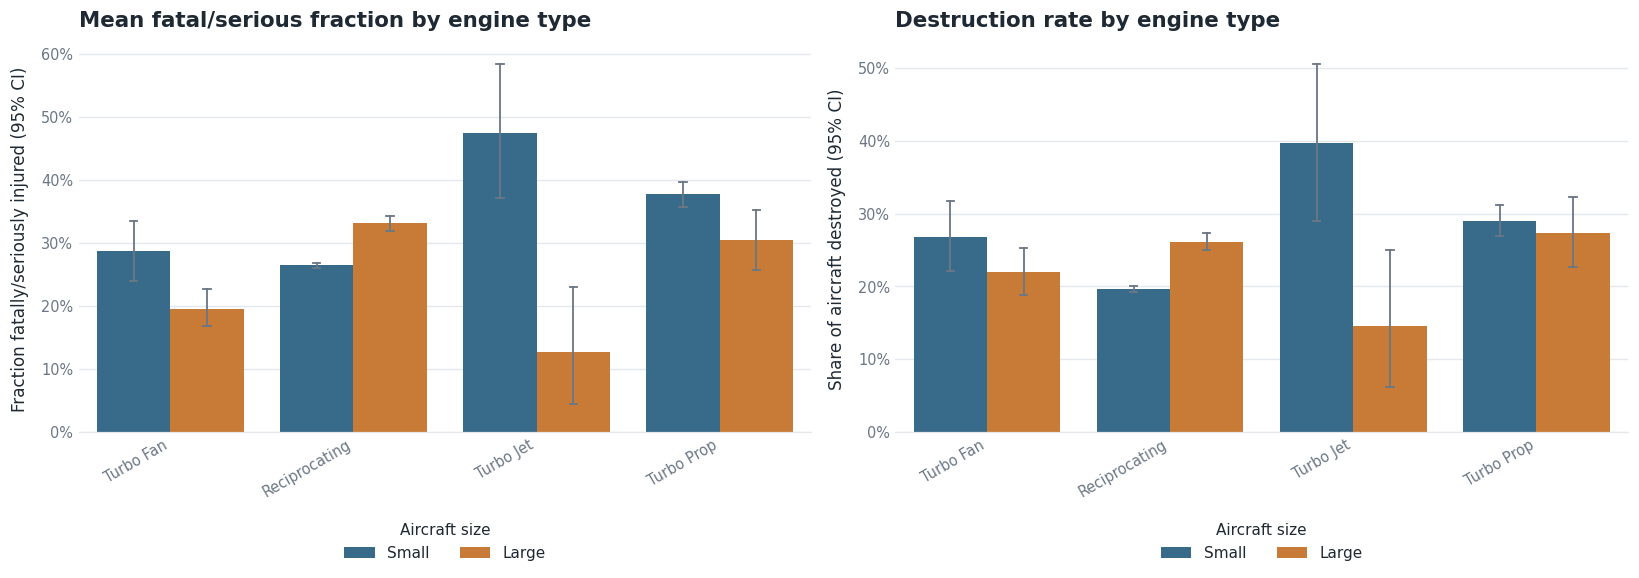

n  mean_fsr  fsr_lo  fsr_hi  destroyed_rate  \
Engine.Type   Aircraft.Size                                                    
Reciprocating Large           5303     0.331   0.319   0.343           0.261   
              Small          45382     0.265   0.261   0.269           0.196   
Turbo Fan     Large            641     0.196   0.167   0.225           0.220   
              Small            302     0.287   0.238   0.336           0.268   
Turbo Jet     Large             48     0.127   0.034   0.220           0.146   
              Small             83     0.474   0.369   0.580           0.398   
Turbo Prop    Large            300     0.305   0.255   0.355           0.273   
              Small           2034     0.377   0.356   0.398           0.290   

                             destroyed_lo  destroyed_hi  
Engine.Type   Aircraft.Size                              
Reciprocating Large                 0.249         0.273  
              Small                 0.193         0.200  
Turbo Fan     Large                 0.190         0.254  
              Small                 0.221         0.321  
Turbo Jet     Large                 0.072         0.272  
              Small                 0.299         0.505  
Turbo Prop    Large                 0.226         0.326  
              Small                 0.270         0.310

Large aircraft - engine type: destroyed vs category chi-square p = 0.0355; fatal/serious fraction Kruskal-Wallis p = 0.0005
Small aircraft - engine type: destroyed vs category chi-square p = 0.0000; fatal/serious fraction Kruskal-Wallis p = 0.0000
(p < 0.05 suggests the category matters; association is not proof of cause.)


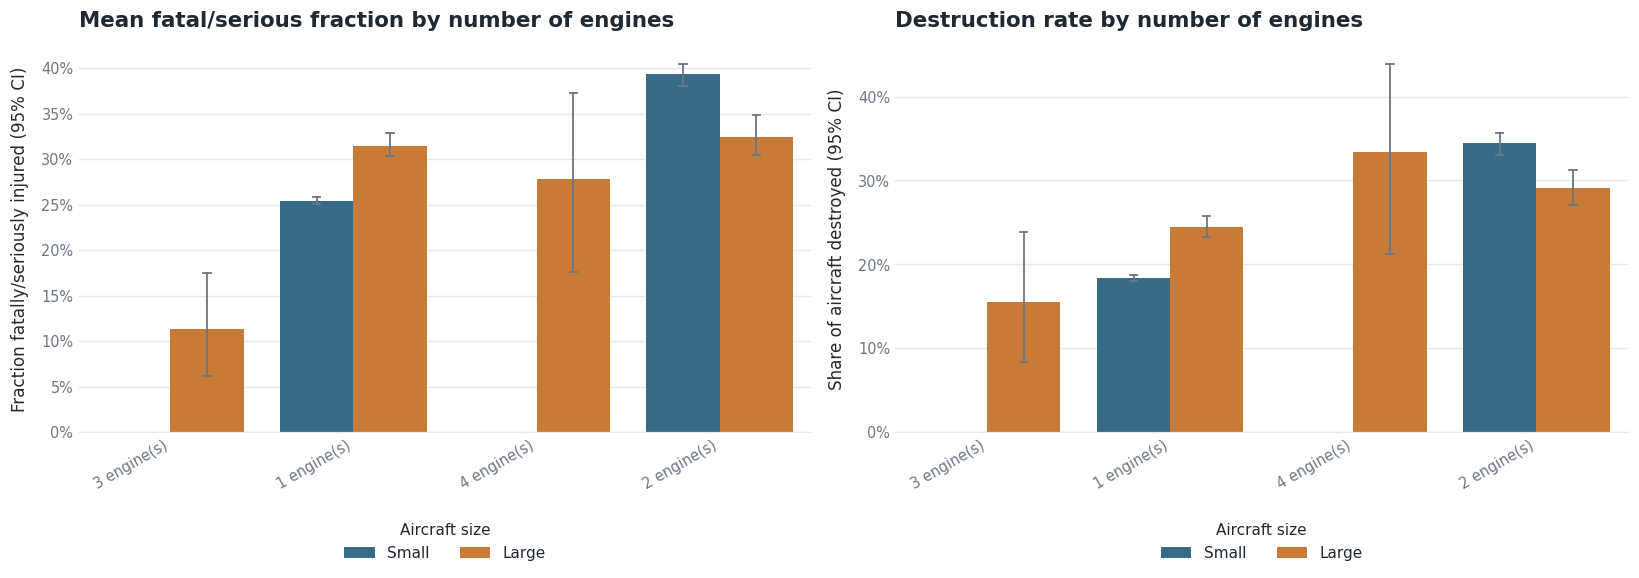

n  mean_fsr  fsr_lo  fsr_hi  destroyed_rate  \
Engines     Aircraft.Size                                                    
1 engine(s) Large           4527     0.315   0.302   0.328           0.245   
            Small          42546     0.255   0.251   0.259           0.183   
2 engine(s) Large           1616     0.325   0.303   0.347           0.291   
            Small           5249     0.393   0.380   0.406           0.344   
3 engine(s) Large             84     0.114   0.056   0.172           0.155   
4 engine(s) Large             66     0.279   0.173   0.384           0.333   

                           destroyed_lo  destroyed_hi  
Engines     Aircraft.Size                              
1 engine(s) Large                 0.233         0.258  
            Small                 0.180         0.187  
2 engine(s) Large                 0.269         0.313  
            Small                 0.332         0.357  
3 engine(s) Large                 0.093         0.247  
4 engine(s) Large                 0.232         0.453

Large aircraft - number of engines: destroyed vs category chi-square p = 0.0002; fatal/serious fraction Kruskal-Wallis p = 0.0133
Small aircraft - number of engines: destroyed vs category chi-square p = 0.0000; fatal/serious fraction Kruskal-Wallis p = 0.0000
(p < 0.05 suggests the category matters; association is not proof of cause.)


In [21]:
clean_df["Engines"] = clean_df["Number.of.Engines"].map(lambda v: f"{int(v)} engine(s)" if pd.notna(v) else np.nan)

factor_analysis("Engine.Type", "engine type")
factor_analysis("Engines", "number of engines")

**Additional factors: engine type and number of engines**

*Write your interpretation here after running the cells above (the numbers change with your data). Suggested points:*
- Are multi-engine aircraft safer than single-engine aircraft within the same size group, or is the difference explained by aircraft size?
- How do turbine engines (turbo prop / turbo fan) compare with piston (reciprocating) engines?
- State clearly where sample sizes are too small to draw a conclusion.

## Summary of recommendations

*Write your final summary here (it can be reused in the README):*
- **Small aircraft (fewer than ~20 people aboard):** recommended makes and plane types, with supporting numbers.
- **Large aircraft (more than 20 people aboard):** recommended makes and plane types, with supporting numbers.
- **Factors:** weather condition and phase of flight (and engine factors if used): what the data shows and what it means for the client.
- **Limitations:** rates are *given an accident* (no flight-hour exposure data), NaNs in some factor columns, minimum sample size of 10 per make/type and 30 per factor category.